# Underspecification Impact Analysis

Comparing pass@k and pass^k metrics between:
- **Original Baseline** (full inference results)
- **After Underspecification** (DELETE severity, 70 tasks)

Model: `gemini-3-pro-preview`

Data source: `experiments/mcpatlas/underspec_full/`

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.family'] = 'serif'
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

In [15]:
# Load the data
# base_path = '../../experiments/mcpatlas/underspec_full'
base_path = '/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230'

# Original baseline results (before underspecification)
og_path = f'{base_path}/baseline_results/per_model/gemini_pass_k_per_task.csv'
# After underspecification
underspec_path = f'{base_path}/run_full_underspec_2_seg_gemini-3-pro-preview_20260122_012432/pass_k_per_task.csv'

df_og = pd.read_csv(og_path)
df_underspec = pd.read_csv(underspec_path)

# Count tasks (excluding AGGREGATE row if present)
og_task_count = len(df_og[df_og['task_id'] != 'AGGREGATE'])
underspec_task_count = len(df_underspec[df_underspec['task_id'] != 'AGGREGATE'])

print(f"Original baseline: {og_task_count} tasks")
print(f"After underspec: {underspec_task_count} tasks")

Original baseline: 222 tasks
After underspec: 222 tasks


## Aggregate Metrics Comparison

In [16]:
# Extract aggregate rows (compute if not present)
def get_aggregate(df):
    """Get aggregate row or compute it if missing."""
    agg_rows = df[df['task_id'] == 'AGGREGATE']
    if len(agg_rows) > 0:
        return agg_rows.iloc[0]
    
    # Compute aggregate from task data
    tasks = df[df['task_id'] != 'AGGREGATE']
    n_tasks = len(tasks)
    return pd.Series({
        'task_id': 'AGGREGATE',
        'n_trials': tasks['n_trials'].sum(),
        'n_success': tasks['n_success'].sum(),
        'pass_rate': tasks['n_success'].sum() / tasks['n_trials'].sum(),
        'pass^1': tasks['pass^1'].mean(),
        'pass^2': tasks['pass^2'].mean(),
        'pass^3': tasks['pass^3'].mean(),
        'pass@1': tasks['pass@1'].mean(),
        'pass@2': tasks['pass@2'].mean(),
        'pass@3': tasks['pass@3'].mean(),
    })

agg_og = get_aggregate(df_og)
agg_underspec = get_aggregate(df_underspec)

# Create comparison dataframe
metrics = ['pass_rate', 'pass^1', 'pass^2', 'pass^3', 'pass@1', 'pass@2', 'pass@3']
comparison = pd.DataFrame({
    'Metric': metrics,
    'Original': [agg_og[m] for m in metrics],
    'After Underspec': [agg_underspec[m] for m in metrics]
})
comparison['Delta'] = comparison['After Underspec'] - comparison['Original']
comparison['% Change'] = (comparison['Delta'] / comparison['Original'] * 100).round(1)

print("\n" + "="*70)
print("AGGREGATE METRICS COMPARISON")
print("="*70)
comparison


AGGREGATE METRICS COMPARISON


,Metric,Original,After Underspec,Delta,% Change
0,pass_rate,0.918919,0.3929,-0.526019,-57.2
1,pass^1,0.918919,0.3919,-0.527019,-57.4
2,pass^2,0.846847,0.1937,-0.653147,-77.1
3,pass^3,0.797297,0.1396,-0.657697,-82.5
4,pass@1,0.918919,0.3919,-0.527019,-57.4
5,pass@2,0.986486,0.6081,-0.378386,-38.4
6,pass@3,1.000000,0.6937,-0.306300,-30.6


/var/folders/4_/cvd4nrqx09z3hfvp3024hv_r0000gq/T/ipykernel_5527/4144673353.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(metrics, rotation=45, ha='right')


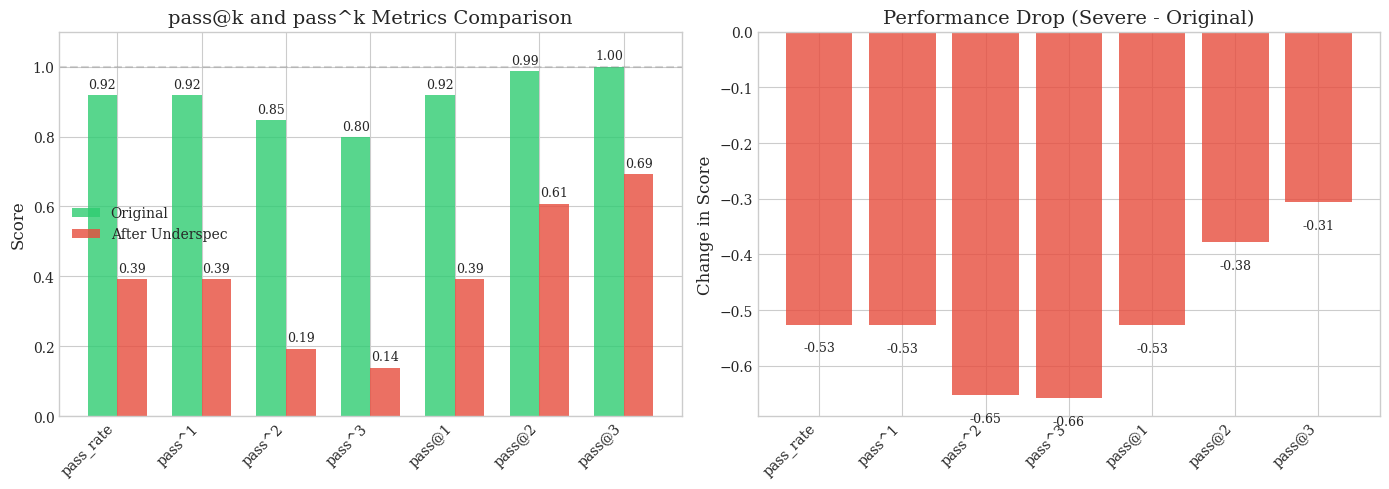

In [17]:
# Visualize aggregate comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart comparison
x = np.arange(len(metrics))
width = 0.35

ax1 = axes[0]
bars1 = ax1.bar(x - width/2, comparison['Original'], width, label='Original', color='#2ecc71', alpha=0.8)
bars2 = ax1.bar(x + width/2, comparison['After Underspec'], width, label='After Underspec', color='#e74c3c', alpha=0.8)

ax1.set_ylabel('Score')
ax1.set_title('pass@k and pass^k Metrics Comparison')
ax1.set_xticks(x)
ax1.set_xticklabels(metrics, rotation=45, ha='right')
ax1.legend()
ax1.set_ylim(0, 1.1)
ax1.axhline(y=1.0, color='gray', linestyle='--', alpha=0.3)

# Add value labels
for bar in bars1:
    height = bar.get_height()
    ax1.annotate(f'{height:.2f}', xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    height = bar.get_height()
    ax1.annotate(f'{height:.2f}', xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9)

# Delta chart
ax2 = axes[1]
colors = ['#e74c3c' if d < 0 else '#2ecc71' for d in comparison['Delta']]
bars3 = ax2.bar(metrics, comparison['Delta'], color=colors, alpha=0.8)
ax2.set_ylabel('Change in Score')
ax2.set_title('Performance Drop (Severe - Original)')
ax2.set_xticklabels(metrics, rotation=45, ha='right')
ax2.axhline(y=0, color='black', linestyle='-', linewidth=0.5)

# Add value labels
for bar, delta in zip(bars3, comparison['Delta']):
    height = bar.get_height()
    ax2.annotate(f'{delta:+.2f}', xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, -12 if height < 0 else 3), textcoords='offset points', 
                ha='center', va='top' if height < 0 else 'bottom', fontsize=9)

plt.tight_layout()
plt.show()

## pass@3 by Removal Variant

Tasks with all 4 conditions: 222

Mean pass@3 by condition:
  Baseline: 1.000
  Top1 Removal: 0.502
  Top2 Removal: 0.599
  Top1+2 Removal: 0.351


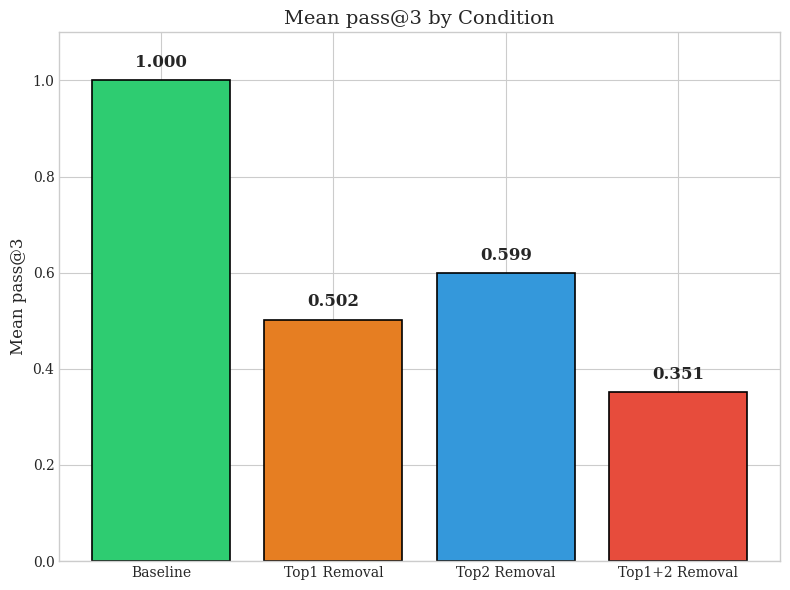

In [ ]:
import sys
import json
from pathlib import Path

# Add the scripts directory to path to import process_underspec_run
scripts_dir = Path(base_path).parent.parent / "scripts"
if str(scripts_dir) not in sys.path:
    sys.path.insert(0, str(scripts_dir))

sys.path.insert(0, '/Users/sam.denton/Code/models/research/lhaw/')


from evaluation.pass_k_metrics import pass_at_k

# Load segment info from JSONs to determine top1/top2 per task
underspec_json_dir = Path(base_path) / "underspec_generation/json"
segment_priority = {}
for json_path in underspec_json_dir.glob("*.json"):
    with open(json_path, "r") as f:
        data = json.load(f)
    task_id = data.get("task", {}).get("id")
    segments = data.get("segments", [])
    segments_sorted = sorted(
        segments,
        key=lambda s: (s.get("priority_score", 0), s.get("criticality", 0)),
        reverse=True,
    )
    top1 = segments_sorted[0]["id"] if len(segments_sorted) > 0 else None
    top2 = segments_sorted[1]["id"] if len(segments_sorted) > 1 else None
    if task_id:
        segment_priority[task_id] = (top1, top2)

# Load evaluation results and completions to map trials to variants
run_dir = Path(base_path) / "run_full_underspec_2_seg_gemini-3-pro-preview_20260122_012432"
evaluation_path = run_dir / "evaluation_full_underspec_2_seg_gemini-3-pro-preview.json"

with open(evaluation_path, "r") as f:
    eval_data = json.load(f)

# Load completions to get prompts per trial
import csv
from io import StringIO

def load_completions(run_path: Path) -> dict[str, list[dict[str, str]]]:
    completions: dict[str, list[dict[str, str]]] = {}
    csv.field_size_limit(10 * 1024 * 1024)
    for csv_path in sorted(run_path.glob("completions_*.csv")):
        csv_text = csv_path.read_text(encoding="utf-8", errors="replace")
        reader = csv.DictReader(StringIO(csv_text))
        for row in reader:
            task_id = row.get("TASK", "")
            prompt = row.get("PROMPT", "")
            if task_id:
                completions.setdefault(task_id, []).append({"prompt": prompt})
    return completions

completions = load_completions(run_dir)

# Load variants from JSON to build prompt -> variant mapping
def _normalize_prompt(prompt: str) -> str:
    return " ".join(prompt.split())

variants_info = {}  # variant_key -> {task, variant_id, underspec_prompt_normalized, removed_segment_ids}
for json_path in underspec_json_dir.glob("*.json"):
    with open(json_path, "r") as f:
        data = json.load(f)
    task_id = data.get("task", {}).get("id")
    for variant in data.get("variants", []):
        variant_id = variant.get("id", "")
        underspec_prompt = variant.get("underspecified_prompt", "")
        removed_segments = variant.get("removed_segments", [])
        removed_ids = [seg["id"] for seg in removed_segments]
        variant_key = f"{task_id}::{variant_id}"
        variants_info[variant_key] = {
            "task": task_id,
            "variant_id": variant_id,
            "underspec_prompt_normalized": _normalize_prompt(underspec_prompt),
            "removed_segment_ids": removed_ids,
        }

# Build prompt index for matching
prompt_index = {}
for vk, info in variants_info.items():
    key = (info["task"], info["underspec_prompt_normalized"])
    prompt_index[key] = vk


def classify_variant(task_id: str, removed_ids: list[str]) -> str:
    top1, top2 = segment_priority.get(task_id, (None, None))
    removed_set = set(removed_ids)
    if len(removed_ids) == 1:
        if removed_ids[0] == top1:
            return "top1 removal"
        if removed_ids[0] == top2:
            return "top2 removal"
        return "other_single"
    if len(removed_ids) == 2 and removed_set == {top1, top2}:
        return "top1and2 removal"
    return "other_multi"


# Build per-variant results by matching prompts
variant_results = {}  # variant_key -> list of scores (0 or 1)
for task_id, task_data in eval_data["tasks"].items():
    task_completions = completions.get(task_id, [])
    results = task_data["results"]
    for i, result in enumerate(results):
        prompt = task_completions[i]["prompt"] if i < len(task_completions) else ""
        normalized = _normalize_prompt(prompt)
        variant_key = prompt_index.get((task_id, normalized))
        if variant_key:
            score = 1 if result["final_score"]["result"] > 0 else 0
            variant_results.setdefault(variant_key, []).append(score)


0    divergent
1    divergent
2     new_task
3       benign
4       benign
Name: ambiguity_class, dtype: object
0    6863f438a500a4b36aab0f24::V_S1_S2_delete
1       6863f438a500a4b36aab0f24::V_S1_delete
2       6863f438a500a4b36aab0f24::V_S2_delete
3    6866d4d2eea665b355a8f8ab::V_S1_S5_delete
4       6866d4d2eea665b355a8f8ab::V_S1_delete
Name: variant_id, dtype: object
{'task': '689cd6f8522029b7ad7b1fe2', 'variant_id': 'V_S1_delete', 'underspec_prompt_normalized': "What is the credit line of the famous Rembrandt painting in the Metropolitan Museum of Art's collection, and what was the full name of the mother of the artist?", 'removed_segment_ids': ['S1']}
689cd6f8522029b7ad7b1fe2::V_S1_S2_delete
[1, 1, 1]
3 3 3
{'task': '68940d8355faa0b720f0b478', 'variant_id': 'V_S1_delete', 'underspec_prompt_normalized': 'I want to get the total units sold on june in the year 2022 in our car dealership, then use that number as an ID to search the museum collection for the artwork with that exact id

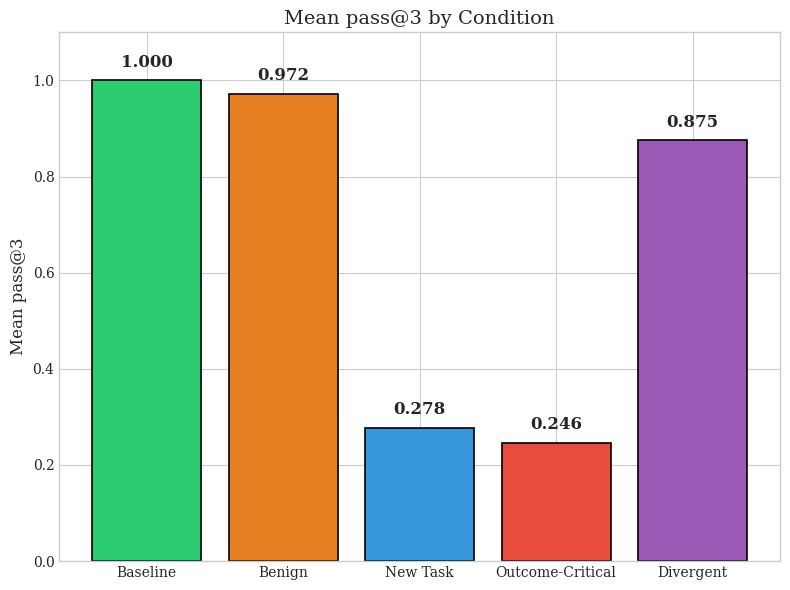

In [57]:
summary_df = pd.read_csv("/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/filtered_underspec.csv")

print(summary_df['ambiguity_class'].head())
print(summary_df['variant_id'].head())

"""
benign              195
new_task            179
outcome-critical    164
divergent   
"""


# Calculate pass@3 per label
rows = []
for vk, scores in variant_results.items():
    info = variants_info.get(vk, {})
    task_id = info.get("task", "")
    removed_ids = info.get("removed_segment_ids", [])

    key = f"{task_id}::{variant_id}"

    if len(summary_df.loc[summary_df['variant_id'] == key]) == 0:
        continue

    n = len(scores)
    c = sum(scores)
    k = min(3, n)
    ambiguity_class = summary_df.loc[summary_df['variant_id'] == key, 'ambiguity_class'].values[0]
    p3 = pass_at_k(n, c, k) if n > 0 else 0.0
    if ambiguity_class == "outcome-critical" and p3 > 0.0:
        print(info)
        print(key)
        print(scores)
        print(n, c, k)
    rows.append({
        "task_id": task_id,
        "variant_key": vk,
        "ambiguity_class": ambiguity_class,
        "n_trials": n,
        "n_success": c,
        "pass@3": p3,
    })

ambiguity_classes = ["benign", "new_task", "outcome-critical", "divergent"]
ambiguity_pass3 = pd.DataFrame(rows)
ambiguity_pass3 = ambiguity_pass3[ambiguity_pass3["ambiguity_class"].isin(ambiguity_classes)]

ambiguity_pass3_wide = (
    ambiguity_pass3.pivot_table(
        index="task_id", columns="ambiguity_class", values="pass@3", aggfunc="mean"
    )
    .reset_index()
)

baseline_pass3 = df_og[df_og["task_id"] != "AGGREGATE"][["task_id", "pass@3"]].rename(
    columns={"pass@3": "baseline pass@3"}
)


# Calculate means
means = {
    "Baseline": baseline_pass3["baseline pass@3"].mean(),
    "Benign": ambiguity_pass3_wide["benign"].mean(),
    "New Task": ambiguity_pass3_wide["new_task"].mean(),
    "Outcome-Critical": ambiguity_pass3_wide["outcome-critical"].mean(),
    "Divergent": ambiguity_pass3_wide["divergent"].mean(),
}

print(f"\nMean pass@3 by condition:")
for label, val in means.items():
    print(f"  {label}: {val:.3f}")

# Bar plot of mean pass@3
fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#2ecc71", "#e67e22", "#3498db", "#e74c3c", "#9b59b6"]
bars = ax.bar(means.keys(), means.values(), color=colors, edgecolor="black", linewidth=1.2)

# Add value labels on bars
for bar, val in zip(bars, means.values()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{val:.3f}",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold",
    )

ax.set_ylim(0, 1.1)
ax.set_ylabel("Mean pass@3")
ax.set_title("Mean pass@3 by Condition")
plt.tight_layout()
plt.show()

In [45]:
summary_df["ambiguity_class"].value_counts()

ambiguity_class
benign              195
new_task            179
outcome-critical    164
divergent           128
Name: count, dtype: int64

## Per-Task Analysis

In [19]:
# Merge per-task data
df_og_tasks = df_og[df_og['task_id'] != 'AGGREGATE'].copy()
df_underspec_tasks = df_underspec[df_underspec['task_id'] != 'AGGREGATE'].copy()

merged = df_og_tasks.merge(df_underspec_tasks, on='task_id', suffixes=('_og', '_underspec'))
merged['pass_rate_delta'] = merged['pass_rate_underspec'] - merged['pass_rate_og']
merged['pass@1_delta'] = merged['pass@1_underspec'] - merged['pass@1_og']
merged['pass^1_delta'] = merged['pass^1_underspec'] - merged['pass^1_og']

print(f"Tasks with decreased performance: {(merged['pass_rate_delta'] < 0).sum()} / {len(merged)}")
print(f"Tasks with unchanged performance: {(merged['pass_rate_delta'] == 0).sum()} / {len(merged)}")
print(f"Tasks with improved performance: {(merged['pass_rate_delta'] > 0).sum()} / {len(merged)}")

Tasks with decreased performance: 197 / 222
Tasks with unchanged performance: 20 / 222
Tasks with improved performance: 5 / 222


In [20]:
# Detailed per-task comparison
task_comparison = merged[['task_id', 'pass_rate_og', 'pass_rate_underspec', 'pass_rate_delta', 
                          'pass@1_og', 'pass@1_underspec', 'pass^1_og', 'pass^1_underspec']].copy()
task_comparison = task_comparison.sort_values('pass_rate_delta')

print("\n" + "="*70)
print("PER-TASK COMPARISON (sorted by performance delta)")
print("="*70)
task_comparison


PER-TASK COMPARISON (sorted by performance delta)


,task_id,pass_rate_og,pass_rate_underspec,pass_rate_delta,pass@1_og,pass@1_underspec,pass^1_og,pass^1_underspec
0,68925f01db31fe35560e3e97,1.0000,0.0000,-1.0000,1.0,0.0,1.0,0.0
148,689e0b1d9c8e2ac413c1f208,1.0000,0.0000,-1.0000,1.0,0.0,1.0,0.0
146,6897a6002b64a8c831efa2fb,1.0000,0.0000,-1.0000,1.0,0.0,1.0,0.0
27,689bd255c0422b257e7dfcae,1.0000,0.0000,-1.0000,1.0,0.0,1.0,0.0
144,6896416f7b30e5d8ccd7c8b4,1.0000,0.0000,-1.0000,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...
196,6896416f7b30e5d8ccd7c913,0.6667,0.7778,0.1111,1.0,0.0,1.0,0.0
206,689e0b1d9c8e2ac413c1f204,0.6667,0.8889,0.2222,1.0,1.0,1.0,1.0
82,689af4e653c3905e7b5b25c1,0.3333,0.5556,0.2223,0.0,0.0,0.0,0.0
97,688fb11183792b921381bd27,0.6667,1.0000,0.3333,1.0,1.0,1.0,1.0


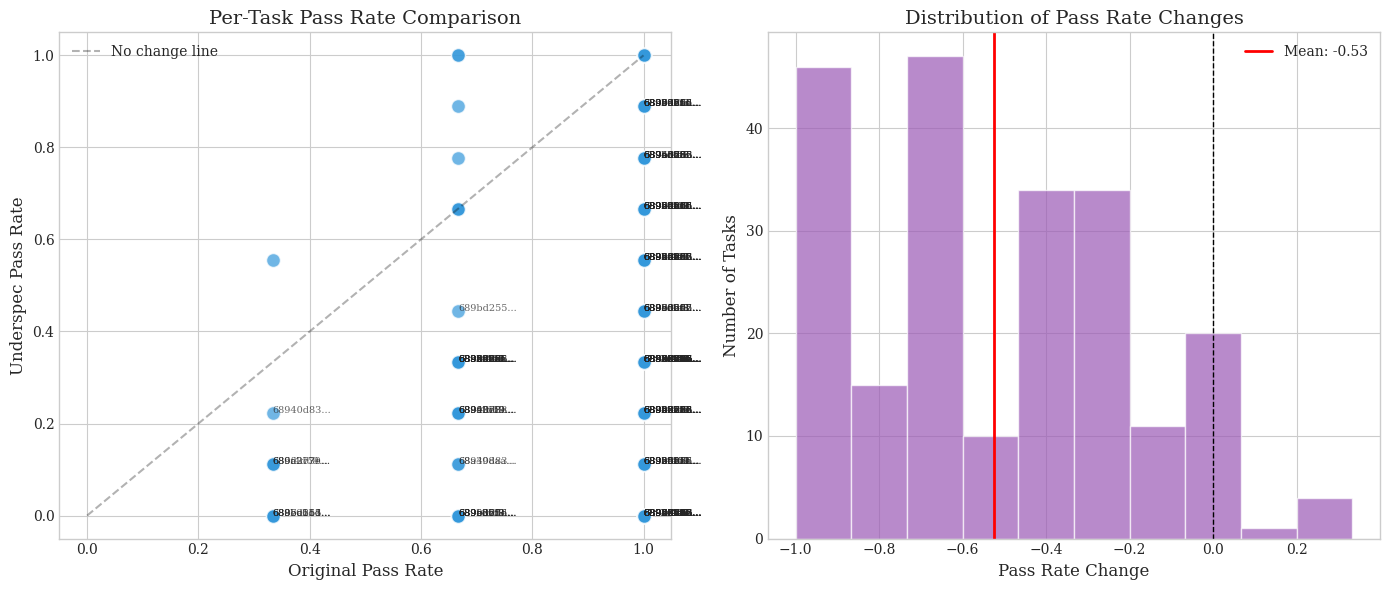

In [21]:
# Visualize per-task changes
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Scatter plot: Original vs Underspec pass rates
ax1 = axes[0]
ax1.scatter(merged['pass_rate_og'], merged['pass_rate_underspec'], alpha=0.7, s=100, c='#3498db', edgecolors='white')
ax1.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='No change line')
ax1.set_xlabel('Original Pass Rate')
ax1.set_ylabel('Underspec Pass Rate')
ax1.set_title('Per-Task Pass Rate Comparison')
ax1.set_xlim(-0.05, 1.05)
ax1.set_ylim(-0.05, 1.05)
ax1.legend()

# Annotate points below the diagonal
for _, row in merged.iterrows():
    if row['pass_rate_underspec'] < row['pass_rate_og'] - 0.1:
        ax1.annotate(row['task_id'][:8] + '...', 
                    (row['pass_rate_og'], row['pass_rate_underspec']),
                    fontsize=7, alpha=0.7)

# Histogram of deltas
ax2 = axes[1]
ax2.hist(merged['pass_rate_delta'], bins=10, color='#9b59b6', alpha=0.7, edgecolor='white')
ax2.axvline(x=0, color='black', linestyle='--', linewidth=1)
ax2.axvline(x=merged['pass_rate_delta'].mean(), color='red', linestyle='-', linewidth=2, 
           label=f'Mean: {merged["pass_rate_delta"].mean():.2f}')
ax2.set_xlabel('Pass Rate Change')
ax2.set_ylabel('Number of Tasks')
ax2.set_title('Distribution of Pass Rate Changes')
ax2.legend()

plt.tight_layout()
plt.show()

## Summary Statistics

In [10]:
print("\n" + "="*70)
print("SUMMARY STATISTICS")
print("="*70)

print(f"\nOverall Performance Impact:")
print(f"   - Original pass rate: {agg_og['pass_rate']:.1%}")
print(f"   - Underspec pass rate: {agg_underspec['pass_rate']:.1%}")
print(f"   - Absolute drop: {agg_underspec['pass_rate'] - agg_og['pass_rate']:+.1%}")
print(f"   - Relative drop: {((agg_underspec['pass_rate'] - agg_og['pass_rate']) / agg_og['pass_rate'] * 100):+.1f}%")

print(f"\npass@1 (probability of at least one success):")
print(f"   - Original: {agg_og['pass@1']:.1%}")
print(f"   - Underspec: {agg_underspec['pass@1']:.1%}")
print(f"   - Change: {agg_underspec['pass@1'] - agg_og['pass@1']:+.1%}")

print(f"\npass^1 (probability all attempts succeed):")
print(f"   - Original: {agg_og['pass^1']:.1%}")
print(f"   - Underspec: {agg_underspec['pass^1']:.1%}")
print(f"   - Change: {agg_underspec['pass^1'] - agg_og['pass^1']:+.1%}")

print(f"\nTask-level impact:")
print(f"   - Tasks degraded: {(merged['pass_rate_delta'] < 0).sum()} ({(merged['pass_rate_delta'] < 0).sum()/len(merged)*100:.1f}%)")
print(f"   - Tasks unchanged: {(merged['pass_rate_delta'] == 0).sum()} ({(merged['pass_rate_delta'] == 0).sum()/len(merged)*100:.1f}%)")
print(f"   - Tasks improved: {(merged['pass_rate_delta'] > 0).sum()} ({(merged['pass_rate_delta'] > 0).sum()/len(merged)*100:.1f}%)")
print(f"   - Mean pass rate delta: {merged['pass_rate_delta'].mean():.2%}")


SUMMARY STATISTICS

Overall Performance Impact:
   - Original pass rate: 93.3%
   - Underspec pass rate: 50.0%
   - Absolute drop: -43.3%
   - Relative drop: -46.4%

pass@1 (probability of at least one success):
   - Original: 97.1%
   - Underspec: 57.1%
   - Change: -40.0%

pass^1 (probability all attempts succeed):
   - Original: 97.1%
   - Underspec: 57.1%
   - Change: -40.0%

Task-level impact:
   - Tasks degraded: 39 (55.7%)
   - Tasks unchanged: 28 (40.0%)
   - Tasks improved: 3 (4.3%)
   - Mean pass rate delta: -43.33%


In [11]:
# Identify most affected tasks
print("\n" + "="*70)
print("MOST AFFECTED TASKS (largest performance drops)")
print("="*70)

most_affected = merged.nsmallest(10, 'pass_rate_delta')[['task_id', 'pass_rate_og', 'pass_rate_underspec', 'pass_rate_delta']]
for _, row in most_affected.iterrows():
    print(f"\n  {row['task_id']}:")
    print(f"    Original: {row['pass_rate_og']:.1%} -> Underspec: {row['pass_rate_underspec']:.1%} (Delta = {row['pass_rate_delta']:+.1%})")


MOST AFFECTED TASKS (largest performance drops)

  68925f01db31fe35560e3e97:
    Original: 100.0% -> Underspec: 0.0% (Delta = -100.0%)

  689e0b1d9c8e2ac413c1f25c:
    Original: 100.0% -> Underspec: 0.0% (Delta = -100.0%)

  689e0b1d9c8e2ac413c1f211:
    Original: 100.0% -> Underspec: 0.0% (Delta = -100.0%)

  689cd6f8522029b7ad7b1fe7:
    Original: 100.0% -> Underspec: 0.0% (Delta = -100.0%)

  689af4e653c3905e7b5b258e:
    Original: 100.0% -> Underspec: 0.0% (Delta = -100.0%)

  68940d8355faa0b720f0b4b4:
    Original: 100.0% -> Underspec: 0.0% (Delta = -100.0%)

  68993ef3cf3e953b8ab83fa9:
    Original: 100.0% -> Underspec: 0.0% (Delta = -100.0%)

  689a373e148a49f91233dfce:
    Original: 100.0% -> Underspec: 0.0% (Delta = -100.0%)

  689f4d693e212e8ef339072a:
    Original: 100.0% -> Underspec: 0.0% (Delta = -100.0%)

  689af4e653c3905e7b5b25c2:
    Original: 100.0% -> Underspec: 0.0% (Delta = -100.0%)


In [12]:
# Robust tasks (maintained performance)
print("\n" + "="*70)
print("ROBUST TASKS (maintained or improved performance)")
print("="*70)

robust = merged[merged['pass_rate_delta'] >= 0][['task_id', 'pass_rate_og', 'pass_rate_underspec', 'pass_rate_delta']]
for _, row in robust.iterrows():
    print(f"\n  {row['task_id']}:")
    print(f"    Original: {row['pass_rate_og']:.1%} -> Underspec: {row['pass_rate_underspec']:.1%} (Delta = {row['pass_rate_delta']:+.1%})")


ROBUST TASKS (maintained or improved performance)

  68925f01db31fe35560e3e9f:
    Original: 100.0% -> Underspec: 100.0% (Delta = +0.0%)

  6896416f7b30e5d8ccd7c901:
    Original: 100.0% -> Underspec: 100.0% (Delta = +0.0%)

  6896416f7b30e5d8ccd7c8f7:
    Original: 100.0% -> Underspec: 100.0% (Delta = +0.0%)

  68993ef3cf3e953b8ab83fe3:
    Original: 100.0% -> Underspec: 100.0% (Delta = +0.0%)

  689f4d693e212e8ef339071f:
    Original: 66.7% -> Underspec: 66.7% (Delta = +0.0%)

  689bd255c0422b257e7dfcad:
    Original: 66.7% -> Underspec: 100.0% (Delta = +33.3%)

  689af4e653c3905e7b5b25b8:
    Original: 100.0% -> Underspec: 100.0% (Delta = +0.0%)

  68925f01db31fe35560e3ea2:
    Original: 100.0% -> Underspec: 100.0% (Delta = +0.0%)

  68993ef3cf3e953b8ab83fd3:
    Original: 100.0% -> Underspec: 100.0% (Delta = +0.0%)

  689cd6f8522029b7ad7b202a:
    Original: 66.7% -> Underspec: 66.7% (Delta = +0.0%)

  68925f01db31fe35560e3e85:
    Original: 66.7% -> Underspec: 100.0% (Delta = +33.

## Underspec Run Analysis by Dimension

The following analysis takes an underspecified run directory as input and computes:
- **pass@3**: Probability that at least one of 3 samples passes
- **Avg. Checkpoint Progress**: Average coverage score across all trials

Metrics are broken down by:
1. **Baseline** (overall aggregate)
2. **Each dimension type** (e.g., goal, constraint, input, context)

In [137]:
# ============================================================================
# Underspecification Run Analysis by Dimension
# ============================================================================
# This analysis takes an underspecified run directory and shows:
# - pass@3 and avg checkpoint progress for baseline and each dimension type
# - Includes count (n) for each category

import pandas as pd
import numpy as np
import ast
from pathlib import Path

def analyze_underspec_run(run_dir: str, prompts_csv_path: str = None, baseline_scored_path: str = None):
    """
    Analyze an underspecified run by dimension type.
    
    Args:
        run_dir: Path to the underspecified run directory 
                 (e.g., run_sampled_underspecified_claude-opus-4-5-20251101_20260123_060406)
        prompts_csv_path: Path to the sampled_filtered_baseline_prompts.csv file.
                          If None, will try to find it in parent directory.
        baseline_scored_path: Path to baseline scored CSV (e.g., claude_combined_scored.csv).
                              If None, will try to find it in baseline_results/per_model/.
    
    Returns:
        DataFrame with aggregated results by dimension type
    """
    run_path = Path(run_dir)
    
    # Auto-detect paths if not provided
    if prompts_csv_path is None:
        prompts_csv_path = run_path.parent / "sampled_filtered_baseline_prompts.csv"
    
    if baseline_scored_path is None:
        raise ValueError("baseline_scored_path is required (e.g., .../baseline_results/per_model/claude_combined_scored.csv)")
    
    # Load prompts metadata (each row is one variant)
    prompts_df = pd.read_csv(prompts_csv_path)
    prompts_df['row_idx'] = prompts_df.index
    
    # --- VERIFICATION: Load completions to verify prompt matching ---
    underspec_completions = pd.read_csv(list(run_path.glob("completions_*.csv"))[0])
    
    # Handle two completions formats:
    # 1. Standard underspec: has TASK (integer index)
    # 2. With_user runs: has variant_id and task columns
    if 'TASK' in underspec_completions.columns:
        # Standard format - use TASK integer index
        prompts_indices = set(prompts_df.index)
        completions_tasks = set(underspec_completions['TASK'].astype(int))
        
        assert len(prompts_indices & completions_tasks) == len(prompts_df), \
            f"Task index mismatch! Expected {len(prompts_df)}, got {len(prompts_indices & completions_tasks)}"
        
        for i, row in prompts_df.head(3).iterrows():
            comp_row = underspec_completions[underspec_completions['TASK'] == i]
            assert len(comp_row) > 0, f"Task index {i} not found in underspec completions!"
            assert row['underspec_prompt'][:100] == comp_row['PROMPT'].iloc[0][:100], \
                f"Underspec prompt mismatch for task {i}!"
    else:
        # With_user format - use variant_id
        prompts_variants = set(prompts_df['variant_id'])
        completions_variants = set(underspec_completions['variant_id'])
        
        assert len(prompts_variants & completions_variants) == len(prompts_df), \
            f"Variant mismatch! Expected {len(prompts_df)}, got {len(prompts_variants & completions_variants)}"
        
        for i, row in prompts_df.head(3).iterrows():
            comp_row = underspec_completions[underspec_completions['variant_id'] == row['variant_id']]
            assert len(comp_row) > 0, f"Variant {row['variant_id']} not found!"
            assert row['underspec_prompt'][:100] == comp_row['PROMPT'].iloc[0][:100], \
                f"Prompt mismatch for variant {row['variant_id']}!"
    
    print("✓ Verification passed: prompt content match!")
    
    # Load baseline scored and compute avg coverage per task (join on original task ID)
    baseline_df = pd.read_csv(baseline_scored_path)
    baseline_coverage = baseline_df.groupby('TASK')['coverage_score'].mean().reset_index()
    baseline_coverage.columns = ['task', 'baseline_coverage']
    
    # Merge baseline coverage using 'task' column (original task ID, not variant)
    prompts_df = prompts_df.merge(baseline_coverage, on='task', how='left')
    
    # Load underspec pass@k results
    pass_k_path = run_path / "pass_k_per_task.csv"
    pass_k_df = pd.read_csv(pass_k_path)
    pass_k_df = pass_k_df[pass_k_df['task_id'] != 'AGGREGATE'].copy()
    
    # Detect if task_id is numeric index or task ID string
    first_task_id = str(pass_k_df['task_id'].iloc[0])
    if first_task_id.isdigit():
        # Numeric index - use row_idx join
        prompts_df['join_key'] = prompts_df.index
        pass_k_df['join_key'] = pass_k_df['task_id'].astype(int)
    else:
        # Task ID string - join on task column
        prompts_df['join_key'] = prompts_df['task']
        pass_k_df['join_key'] = pass_k_df['task_id']
    
    # Load underspec coverage scores
    scores_dirs = sorted(run_path.glob("scores_*/"))
    all_scores = []
    for scores_dir in scores_dirs:
        for sf in scores_dir.glob("scored_*.csv"):
            df = pd.read_csv(sf)
            all_scores.append(df)
    
    if all_scores:
        scores_df = pd.concat(all_scores, ignore_index=True)
        underspec_coverage = scores_df.groupby('TASK')['coverage_score'].mean().reset_index()
        
        # Check if TASK is integer index or string task ID
        first_task = str(underspec_coverage['TASK'].iloc[0])
        if first_task.isdigit():
            # Integer index - join on row_idx
            underspec_coverage.columns = ['row_idx', 'underspec_coverage']
            underspec_coverage['row_idx'] = underspec_coverage['row_idx'].astype(int)
        else:
            # String task ID - join on task column
            underspec_coverage.columns = ['task', 'underspec_coverage']
    else:
        underspec_coverage = pd.DataFrame(columns=['row_idx', 'underspec_coverage'])
    
    # Merge underspec results
    merged = prompts_df.merge(pass_k_df[['join_key', 'pass@3']], on='join_key', how='left')
    merged = merged.rename(columns={'pass@3': 'underspec_pass@3'})
    
    # Merge coverage - use appropriate key based on what's in underspec_coverage
    if 'row_idx' in underspec_coverage.columns:
        merged = merged.merge(underspec_coverage, on='row_idx', how='left')
    else:
        merged = merged.merge(underspec_coverage, on='task', how='left')
    
    # Parse dimension column (it's a JSON-like list)
    def parse_dimensions(val):
        if pd.isna(val):
            return []
        try:
            return ast.literal_eval(val)
        except:
            return [str(val)]
    
    merged['dimension_list'] = merged['dimension'].apply(parse_dimensions)
    
    # Explode dimensions so each row has one dimension
    exploded = merged.explode('dimension_list')
    exploded = exploded.rename(columns={'dimension_list': 'dim'})
    
    # BASELINE stats - using baseline_pass_at_3 and baseline_coverage
    baseline_stats = {
        'category': 'BASELINE (before underspec)',
        'n': len(merged),
        'pass@3': merged['baseline_pass_at_3'].mean(),
        'avg_checkpoint_progress': merged['baseline_coverage'].mean()
    }
    
    # UNDERSPEC aggregate stats
    underspec_stats = {
        'category': 'UNDERSPEC (all tasks)',
        'n': len(merged),
        'pass@3': merged['underspec_pass@3'].mean(),
        'avg_checkpoint_progress': merged['underspec_coverage'].mean()
    }
    
    # Compute per-dimension metrics for underspec
    dim_stats = []
    
    for dim, group in exploded.groupby('dim'):
        if pd.isna(dim):
            continue
        stats = {
            'category': f"dim: {dim}",
            'n': len(group),
            'pass@3': group['underspec_pass@3'].mean(),
            'avg_checkpoint_progress': group['underspec_coverage'].mean()
        }
        dim_stats.append(stats)
    
    # Combine results
    results = [baseline_stats, underspec_stats] + sorted(dim_stats, key=lambda x: x['n'], reverse=True)
    results_df = pd.DataFrame(results)
    
    return results_df, merged


# Example usage - set the run directory and baseline scored path
# run_dir = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_gemini-3-pro-preview_20260123_060447"
# baseline_scored_path = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/baseline_results/per_model/gemini_combined_scored.csv"
run_dir = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_gpt-5.2_20260124_023055"
baseline_scored_path = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/baseline_results/per_model/gpt_combined_scored.csv"
run_dir = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_with_user_gpt-5.2_20260124_023126"
baseline_scored_path = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/baseline_results/per_model/gpt_combined_scored.csv"

results_df, merged_data = analyze_underspec_run(run_dir, baseline_scored_path=baseline_scored_path)

# Display results
print("=" * 80)
print("UNDERSPEC RUN ANALYSIS BY DIMENSION")
print("=" * 80)
print(f"\nRun: {Path(run_dir).name}")
print()

# Format and display results
display_df = results_df.copy()
display_df['pass@3'] = display_df['pass@3'].apply(lambda x: f"{x:.1%}" if pd.notna(x) else "N/A")
display_df['avg_checkpoint_progress'] = display_df['avg_checkpoint_progress'].apply(
    lambda x: f"{x:.3f}" if pd.notna(x) else "N/A"
)
print(display_df.to_string(index=False))

✓ Verification passed: prompt content match!
UNDERSPEC RUN ANALYSIS BY DIMENSION

Run: run_sampled_underspecified_with_user_gpt-5.2_20260124_023126

                   category   n pass@3 avg_checkpoint_progress
BASELINE (before underspec) 100 100.0%                   0.847
      UNDERSPEC (all tasks) 100  59.0%                   0.521
                  dim: goal  52  50.0%                   0.469
            dim: constraint  49  67.3%                   0.510
                 dim: input  49  63.3%                   0.607
               dim: context  12  58.3%                   0.553


In [79]:
run_dir = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_with_user_gpt-5.2_20260124_023126"
baseline_scored_path = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/baseline_results/per_model/gpt_combined_scored.csv"
# run_dir = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_with_user_claude-opus-4-5-20251101_20260124_023156"
# baseline_scored_path = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/baseline_results/per_model/claude_combined_scored.csv"
# run_dir = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_with_user_gemini-3-pro-preview_20260124_023206"
# baseline_scored_path = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/baseline_results/per_model/gemini_combined_scored.csv"



results_df, merged_data = analyze_underspec_run(run_dir, baseline_scored_path=baseline_scored_path)

# Display results
print("=" * 80)
print("UNDERSPEC RUN ANALYSIS WITH_USER BY DIMENSION")
print("=" * 80)
print(f"\nRun: {Path(run_dir).name}")
print()

# Format and display results
display_df = results_df.copy()
display_df['pass@3'] = display_df['pass@3'].apply(lambda x: f"{x:.1%}" if pd.notna(x) else "N/A")
display_df['avg_checkpoint_progress'] = display_df['avg_checkpoint_progress'].apply(
    lambda x: f"{x:.3f}" if pd.notna(x) else "N/A"
)
print(display_df.to_string(index=False))

✓ Verification passed: variant_id and prompt content match!
UNDERSPEC RUN ANALYSIS WITH_USER BY DIMENSION

Run: run_sampled_underspecified_with_user_gpt-5.2_20260124_023126

                   category   n pass@3 avg_checkpoint_progress
BASELINE (before underspec) 100 100.0%                   0.847
      UNDERSPEC (all tasks) 100  59.0%                   0.521
                  dim: goal  52  50.0%                   0.469
            dim: constraint  49  67.3%                   0.510
                 dim: input  49  63.3%                   0.607
               dim: context  12  58.3%                   0.553


In [72]:
# ============================================================================
# Underspecification Run Analysis by Dimension (v2 - using baseline run)
# ============================================================================
# Same as above but takes a baseline RUN directory instead of pre-computed CSV

def analyze_underspec_run_v2(underspec_run_dir: str, baseline_run_dir: str, prompts_csv_path: str = None):
    """
    Analyze an underspecified run by dimension type, using a baseline run directory.
    
    Args:
        underspec_run_dir: Path to the underspecified run directory
        baseline_run_dir: Path to the baseline run directory (e.g., run_sampled_baseline_*)
        prompts_csv_path: Path to sampled_filtered_baseline_prompts.csv
    """
    underspec_path = Path(underspec_run_dir)
    baseline_path = Path(baseline_run_dir)
    
    if prompts_csv_path is None:
        prompts_csv_path = underspec_path.parent / "sampled_filtered_baseline_prompts.csv"
    
    # Load prompts metadata
    prompts_df = pd.read_csv(prompts_csv_path)
    
    # --- VERIFICATION: Load completions to verify prompt matching ---
    underspec_completions = pd.read_csv(list(underspec_path.glob("completions_*.csv"))[0])
    baseline_completions = pd.read_csv(list(baseline_path.glob("completions_*.csv"))[0])
    
    # Verify variant_id alignment
    prompts_variants = set(prompts_df['variant_id'])
    underspec_variants = set(underspec_completions['variant_id'])
    baseline_variants = set(baseline_completions['variant_id'])
    
    assert len(prompts_variants & underspec_variants) == len(prompts_df), \
        f"Underspec variant mismatch! Expected {len(prompts_df)}, got {len(prompts_variants & underspec_variants)}"
    assert len(prompts_variants & baseline_variants) == len(prompts_df), \
        f"Baseline variant mismatch! Expected {len(prompts_df)}, got {len(prompts_variants & baseline_variants)}"
    
    # Verify prompt content matches for first 3 rows
    for i, row in prompts_df.head(3).iterrows():
        variant_id = row['variant_id']
        
        # Check underspec prompt
        comp_row = underspec_completions[underspec_completions['variant_id'] == variant_id]
        assert len(comp_row) > 0, f"Variant {variant_id} not found in underspec completions!"
        assert row['underspec_prompt'][:100] == comp_row['PROMPT'].iloc[0][:100], \
            f"Underspec prompt mismatch for {variant_id}!"
        
        # Check baseline prompt
        comp_row = baseline_completions[baseline_completions['variant_id'] == variant_id]
        assert len(comp_row) > 0, f"Variant {variant_id} not found in baseline completions!"
        assert row['original_prompt'][:100] == comp_row['original_prompt'].iloc[0][:100], \
            f"Baseline prompt mismatch for {variant_id}!"
    
    print("✓ Verification passed: variant_id and prompt content match!")
    
    # --- Load baseline data from run directory ---
    baseline_pass_k = pd.read_csv(baseline_path / "pass_k_per_task.csv")
    baseline_pass_k = baseline_pass_k[baseline_pass_k['task_id'] != 'AGGREGATE'].copy()
    
    # Detect task_id format for baseline
    first_baseline_id = str(baseline_pass_k['task_id'].iloc[0])
    if first_baseline_id.isdigit():
        prompts_df['baseline_join_key'] = prompts_df.index
        baseline_pass_k['join_key'] = baseline_pass_k['task_id'].astype(int)
    else:
        prompts_df['baseline_join_key'] = prompts_df['task']
        baseline_pass_k['join_key'] = baseline_pass_k['task_id']
    
    # Load baseline coverage scores
    baseline_scores_dirs = sorted(baseline_path.glob("scores_*/"))
    baseline_scores = []
    for scores_dir in baseline_scores_dirs:
        for sf in scores_dir.glob("scored_*.csv"):
            df = pd.read_csv(sf)
            baseline_scores.append(df)
    
    if baseline_scores:
        baseline_scores_df = pd.concat(baseline_scores, ignore_index=True)
        baseline_coverage = baseline_scores_df.groupby('TASK')['coverage_score'].mean().reset_index()
        baseline_coverage.columns = ['task', 'baseline_coverage']
    else:
        baseline_coverage = pd.DataFrame(columns=['task', 'baseline_coverage'])
    
    # Merge baseline pass@3
    prompts_df = prompts_df.merge(
        baseline_pass_k[['join_key', 'pass@3']].rename(columns={'join_key': 'baseline_join_key', 'pass@3': 'baseline_pass@3'}),
        on='baseline_join_key', how='left'
    )
    # Merge baseline coverage
    prompts_df = prompts_df.merge(baseline_coverage, on='task', how='left')
    
    # --- Load underspec data ---
    underspec_pass_k = pd.read_csv(underspec_path / "pass_k_per_task.csv")
    underspec_pass_k = underspec_pass_k[underspec_pass_k['task_id'] != 'AGGREGATE'].copy()
    
    # Detect task_id format for underspec
    first_underspec_id = str(underspec_pass_k['task_id'].iloc[0])
    if first_underspec_id.isdigit():
        prompts_df['underspec_join_key'] = prompts_df.index
        underspec_pass_k['join_key'] = underspec_pass_k['task_id'].astype(int)
    else:
        prompts_df['underspec_join_key'] = prompts_df['task']
        underspec_pass_k['join_key'] = underspec_pass_k['task_id']
    
    # Load underspec coverage scores
    underspec_scores_dirs = sorted(underspec_path.glob("scores_*/"))
    underspec_scores = []
    for scores_dir in underspec_scores_dirs:
        for sf in scores_dir.glob("scored_*.csv"):
            df = pd.read_csv(sf)
            underspec_scores.append(df)
    
    if underspec_scores:
        underspec_scores_df = pd.concat(underspec_scores, ignore_index=True)
        underspec_coverage = underspec_scores_df.groupby('TASK')['coverage_score'].mean().reset_index()
        underspec_coverage.columns = ['task', 'underspec_coverage']
    else:
        underspec_coverage = pd.DataFrame(columns=['task', 'underspec_coverage'])
    
    # Merge underspec pass@3
    merged = prompts_df.merge(
        underspec_pass_k[['join_key', 'pass@3']].rename(columns={'join_key': 'underspec_join_key', 'pass@3': 'underspec_pass@3'}),
        on='underspec_join_key', how='left'
    )
    # Merge underspec coverage
    merged = merged.merge(underspec_coverage, on='task', how='left')
    
    # Parse dimension column
    def parse_dimensions(val):
        if pd.isna(val):
            return []
        try:
            return ast.literal_eval(val)
        except:
            return [str(val)]
    
    merged['dimension_list'] = merged['dimension'].apply(parse_dimensions)
    exploded = merged.explode('dimension_list')
    exploded = exploded.rename(columns={'dimension_list': 'dim'})
    
    # BASELINE stats (from baseline run)
    baseline_stats = {
        'category': 'BASELINE (before underspec)',
        'n': len(merged),
        'pass@3': merged['baseline_pass@3'].mean(),
        'avg_checkpoint_progress': merged['baseline_coverage'].mean()
    }
    
    # UNDERSPEC aggregate stats
    underspec_stats = {
        'category': 'UNDERSPEC (all tasks)',
        'n': len(merged),
        'pass@3': merged['underspec_pass@3'].mean(),
        'avg_checkpoint_progress': merged['underspec_coverage'].mean()
    }
    
    # Per-dimension metrics
    dim_stats = []
    for dim, group in exploded.groupby('dim'):
        if pd.isna(dim):
            continue
        stats = {
            'category': f"dim: {dim}",
            'n': len(group),
            'pass@3': group['underspec_pass@3'].mean(),
            'avg_checkpoint_progress': group['underspec_coverage'].mean()
        }
        dim_stats.append(stats)
    
    results = [baseline_stats, underspec_stats] + sorted(dim_stats, key=lambda x: x['n'], reverse=True)
    results_df = pd.DataFrame(results)
    
    return results_df, merged


# Example usage - set both run directories
underspec_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_gemini-3-flash-preview_20260126_234630"
baseline_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_baseline_gemini-3-flash-preview_20260126_234553"

results_df, merged_data = analyze_underspec_run_v2(underspec_run, baseline_run)

# Display results
print("=" * 80)
print("UNDERSPEC RUN ANALYSIS BY DIMENSION (using baseline run)")
print("=" * 80)
print(f"\nUnderspec: {Path(underspec_run).name}")
print(f"Baseline:  {Path(baseline_run).name}")
print()

display_df = results_df.copy()
display_df['pass@3'] = display_df['pass@3'].apply(lambda x: f"{x:.1%}" if pd.notna(x) else "N/A")
display_df['avg_checkpoint_progress'] = display_df['avg_checkpoint_progress'].apply(
    lambda x: f"{x:.3f}" if pd.notna(x) else "N/A"
)
print(display_df.to_string(index=False))

UNDERSPEC RUN ANALYSIS BY DIMENSION (using baseline run)

Underspec: run_sampled_underspecified_gemini-3-flash-preview_20260126_234630
Baseline:  run_sampled_baseline_gemini-3-flash-preview_20260126_234553

                   category   n pass@3 avg_checkpoint_progress
BASELINE (before underspec) 100  93.0%                   0.856
      UNDERSPEC (all tasks) 100  44.0%                   0.449
                  dim: goal  52  42.3%                   0.463
            dim: constraint  49  32.7%                   0.370
                 dim: input  49  38.8%                   0.371
               dim: context  12  91.7%                   0.819


In [80]:
# Example usage - set both run directories
# underspec_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_with_user_gemini-3-flash-preview_20260126_234644"
# baseline_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_baseline_gemini-3-flash-preview_20260126_234553"
underspec_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_with_user_claude-sonnet-4-5-20250929_20260126_203030"
baseline_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_baseline_claude-sonnet-4-5-20250929_20260126_203509"

results_df, merged_data = analyze_underspec_run_v2(underspec_run, baseline_run)

# Display results
print("=" * 80)
print("UNDERSPEC RUN ANALYSIS WITH USER BY DIMENSION (using baseline run)")
print("=" * 80)
print(f"\nUnderspec: {Path(underspec_run).name}")
print(f"Baseline:  {Path(baseline_run).name}")
print()

display_df = results_df.copy()
display_df['pass@3'] = display_df['pass@3'].apply(lambda x: f"{x:.1%}" if pd.notna(x) else "N/A")
display_df['avg_checkpoint_progress'] = display_df['avg_checkpoint_progress'].apply(
    lambda x: f"{x:.3f}" if pd.notna(x) else "N/A"
)
print(display_df.to_string(index=False))

UNDERSPEC RUN ANALYSIS WITH USER BY DIMENSION (using baseline run)

Underspec: run_sampled_underspecified_with_user_claude-sonnet-4-5-20250929_20260126_203030
Baseline:  run_sampled_baseline_claude-sonnet-4-5-20250929_20260126_203509

                   category   n pass@3 avg_checkpoint_progress
BASELINE (before underspec) 100  87.0%                   0.828
      UNDERSPEC (all tasks) 100  71.0%                   0.613
                  dim: goal  52  65.4%                   0.612
            dim: constraint  49  75.5%                   0.632
                 dim: input  49  67.3%                   0.590
               dim: context  12  75.0%                   0.582


In [163]:
# ============================================================================
# Compare Underspec runs: with vs without ask_user tool
# ============================================================================
# Shows metrics with improvement from ask_user in parentheses

import json

def count_ask_user_calls(conv_str: str) -> int:
    """Count number of ask_user tool calls in a conversation."""
    try:
        conv = json.loads(conv_str)
        count = 0
        for msg in conv:
            if msg.get("role") == "assistant" and msg.get("tool_calls"):
                for tc in msg["tool_calls"]:
                    name = tc.get("function", {}).get("name", "")
                    if name == "ask_user":
                        count += 1
        return count
    except Exception:
        return 0


def load_ask_user_stats(run_dir: str) -> dict:
    """Load ask_user call statistics from a run directory.
    
    Returns:
        dict with:
            - pct_tasks_with_ask_user: % of tasks where ask_user was called at least once
            - total_ask_user_calls: total number of ask_user calls across all tasks/trials
            - mean_ask_user_per_task: mean ask_user calls per task
            - mean_calls_per_trial_when_used: avg calls per trial, only counting trials with at least 1 call
    """
    run_path = Path(run_dir)
    scores_dirs = sorted(run_path.glob("scores_*"))
    
    if not scores_dirs:
        return {"pct_tasks_with_ask_user": 0, "total_ask_user_calls": 0, "mean_ask_user_per_task": 0, "mean_calls_per_trial_when_used": 0}
    
    all_counts = []
    for scores_dir in scores_dirs:
        for csv_path in scores_dir.glob("scored_*.csv"):
            df = pd.read_csv(csv_path)
            if "raw_conversation_history" not in df.columns or "TASK" not in df.columns:
                continue
            df["ask_user_count"] = df["raw_conversation_history"].apply(count_ask_user_calls)
            all_counts.append(df[["TASK", "ask_user_count"]])
    
    if not all_counts:
        return {"pct_tasks_with_ask_user": 0, "total_ask_user_calls": 0, "mean_ask_user_per_task": 0, "mean_calls_per_trial_when_used": 0}
    
    combined = pd.concat(all_counts, ignore_index=True)
    total_calls = int(combined["ask_user_count"].sum())
    
    # Per-task stats (sum across trials for each task)
    per_task = combined.groupby("TASK")["ask_user_count"].sum()
    n_tasks_with_calls = (per_task > 0).sum()
    n_tasks = len(per_task)
    
    # Avg calls per trial when ask_user was used (exclude trials with 0 calls)
    trials_with_calls = combined[combined["ask_user_count"] > 0]
    mean_when_used = trials_with_calls["ask_user_count"].mean() if len(trials_with_calls) > 0 else 0
    
    return {
        "pct_tasks_with_ask_user": n_tasks_with_calls / n_tasks if n_tasks > 0 else 0,
        "total_ask_user_calls": total_calls,
        "mean_ask_user_per_task": per_task.mean() if n_tasks > 0 else 0,
        "mean_calls_per_trial_when_used": mean_when_used,
    }


def compare_with_ask_user(
    underspec_run: str,
    underspec_with_user_run: str, 
    baseline_run_or_path: str,
    use_v2: bool = True
):
    """
    Compare underspec runs with and without ask_user tool.
    Shows metrics with improvement from ask_user in parentheses.
    
    Args:
        underspec_run: Path to underspec run WITHOUT ask_user tool
        underspec_with_user_run: Path to underspec run WITH ask_user tool
        baseline_run_or_path: Path to baseline run (for v2) or baseline_scored_path (for v1)
        use_v2: If True, use analyze_underspec_run_v2 (baseline is a run dir)
                If False, use analyze_underspec_run (baseline is a scored CSV path)
    
    Returns:
        DataFrame with formatted comparison
    """
    # Run analysis for both using the specified function
    if use_v2:
        df_no_user, _ = analyze_underspec_run_v2(underspec_run, baseline_run_or_path)
        df_with_user, _ = analyze_underspec_run_v2(underspec_with_user_run, baseline_run_or_path)
    else:
        df_no_user, _ = analyze_underspec_run(underspec_run, baseline_scored_path=baseline_run_or_path)
        df_with_user, _ = analyze_underspec_run(underspec_with_user_run, baseline_scored_path=baseline_run_or_path)
    
    # Merge on category
    comparison = df_no_user.merge(
        df_with_user[['category', 'pass@3', 'avg_checkpoint_progress']],
        on='category',
        suffixes=('_no_user', '_with_user')
    )
    
    # Calculate improvements
    comparison['pass@3_improvement'] = comparison['pass@3_with_user'] - comparison['pass@3_no_user']
    comparison['checkpoint_improvement'] = comparison['avg_checkpoint_progress_with_user'] - comparison['avg_checkpoint_progress_no_user']
    
    # Format output: base value (without ask_user) with improvement in parentheses
    def format_with_improvement(base_val, improvement):
        if pd.isna(base_val):
            return "N/A"
        if pd.isna(improvement):
            return f"{base_val*100:.1f}%"
        sign = "+" if improvement >= 0 else ""
        return f"{base_val*100:.1f}% ({sign}{improvement*100:.1f}%)"
    
    comparison['pass@3'] = comparison.apply(
        lambda r: format_with_improvement(r['pass@3_no_user'], r['pass@3_improvement']), axis=1
    )
    comparison['avg_checkpoint_progress'] = comparison.apply(
        lambda r: format_with_improvement(r['avg_checkpoint_progress_no_user'], r['checkpoint_improvement']), axis=1
    )
    
    # Load ask_user stats from with_user run
    ask_user_stats = load_ask_user_stats(underspec_with_user_run)
    
    return comparison[['category', 'n', 'pass@3', 'avg_checkpoint_progress']], ask_user_stats


In [164]:
# Opus4.5

# Example usage
underspec_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_claude-opus-4-5-20251101_20260123_060406"
underspec_with_user_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_with_user_new_claude-opus-4-5-20251101_20260128_044057"
baseline_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/baseline_results/per_model/claude_combined_scored.csv"

result, ask_user_stats = compare_with_ask_user(underspec_run, underspec_with_user_run, baseline_run, use_v2=False)

print("=" * 80)
print("COMPARISON: Underspec with ask_user tool improvement")
print("=" * 80)
print(f"\nWithout ask_user: {Path(underspec_run).name}")
print(f"With ask_user:    {Path(underspec_with_user_run).name}")
print(f"Baseline:         {Path(baseline_run).name}")
print()
print(result.to_string(index=False))

print(f"\n--- ask_user Tool Usage ---")
print(f"Tasks where ask_user was called: {ask_user_stats['pct_tasks_with_ask_user']*100:.1f}%")
print(f"Total ask_user calls: {ask_user_stats['total_ask_user_calls']}")
print(f"Mean ask_user calls per task: {ask_user_stats['mean_ask_user_per_task']:.2f}")
print(f"Avg calls per trial (when used): {ask_user_stats['mean_calls_per_trial_when_used']:.2f}")

✓ Verification passed: prompt content match!
✓ Verification passed: prompt content match!
COMPARISON: Underspec with ask_user tool improvement

Without ask_user: run_sampled_underspecified_claude-opus-4-5-20251101_20260123_060406
With ask_user:    run_sampled_underspecified_with_user_new_claude-opus-4-5-20251101_20260128_044057
Baseline:         claude_combined_scored.csv

                   category   n         pass@3 avg_checkpoint_progress
BASELINE (before underspec) 100 100.0% (+0.0%)           91.1% (+0.0%)
      UNDERSPEC (all tasks) 100 47.0% (+31.0%)          47.9% (+23.1%)
                  dim: goal  52 42.3% (+30.8%)          44.0% (+20.2%)
            dim: constraint  49 36.7% (+40.8%)          41.5% (+30.9%)
                 dim: input  49 40.8% (+42.9%)          39.9% (+32.1%)
               dim: context  12  91.7% (+0.0%)           84.9% (+5.4%)

--- ask_user Tool Usage ---
Tasks where ask_user was called: 73.0%
Total ask_user calls: 207
Mean ask_user calls per task: 2.0

In [172]:
# Gemini-3-Pro

# Example usage
underspec_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_gemini-3-pro-preview_20260123_060447"
underspec_with_user_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_with_user_new_gemini-3-pro-preview_20260128_155002"
# underspec_with_user_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_with_user_gemini-3-pro-preview_20260124_023206"
baseline_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/baseline_results/per_model/gemini_combined_scored.csv"

result, ask_user_stats = compare_with_ask_user(underspec_run, underspec_with_user_run, baseline_run, use_v2=False)

print("=" * 80)
print("COMPARISON: Underspec with ask_user tool improvement")
print("=" * 80)
print(f"\nWithout ask_user: {Path(underspec_run).name}")
print(f"With ask_user:    {Path(underspec_with_user_run).name}")
print(f"Baseline:         {Path(baseline_run).name}")
print()
print(result.to_string(index=False))

print(f"\n--- ask_user Tool Usage ---")
print(f"Tasks where ask_user was called: {ask_user_stats['pct_tasks_with_ask_user']*100:.1f}%")
print(f"Total ask_user calls: {ask_user_stats['total_ask_user_calls']}")
print(f"Mean ask_user calls per task: {ask_user_stats['mean_ask_user_per_task']:.2f}")
print(f"Avg calls per trial (when used): {ask_user_stats['mean_calls_per_trial_when_used']:.2f}")

✓ Verification passed: prompt content match!
✓ Verification passed: prompt content match!
COMPARISON: Underspec with ask_user tool improvement

Without ask_user: run_sampled_underspecified_gemini-3-pro-preview_20260123_060447
With ask_user:    run_sampled_underspecified_with_user_new_gemini-3-pro-preview_20260128_155002
Baseline:         gemini_combined_scored.csv

                   category   n         pass@3 avg_checkpoint_progress
BASELINE (before underspec) 100 100.0% (+0.0%)           90.2% (+0.0%)
      UNDERSPEC (all tasks) 100 46.0% (+26.0%)          46.1% (+21.0%)
                  dim: goal  52 46.2% (+19.2%)          46.9% (+15.8%)
            dim: constraint  49 30.6% (+34.7%)          35.9% (+26.2%)
                 dim: input  49 49.0% (+32.7%)          41.3% (+27.1%)
               dim: context  12  83.3% (+8.3%)           82.8% (+1.3%)

--- ask_user Tool Usage ---
Tasks where ask_user was called: 63.0%
Total ask_user calls: 162
Mean ask_user calls per task: 1.62
Avg ca

In [166]:
# GPT-5.2

# Example usage
underspec_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_gpt-5.2_20260124_023055"
underspec_with_user_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_with_user_new_gpt-5.2_20260128_044134"
baseline_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/baseline_results/per_model/gpt_combined_scored.csv"

result, ask_user_stats = compare_with_ask_user(underspec_run, underspec_with_user_run, baseline_run, use_v2=False)

print("=" * 80)
print("COMPARISON: Underspec with ask_user tool improvement")
print("=" * 80)
print(f"\nWithout ask_user: {Path(underspec_run).name}")
print(f"With ask_user:    {Path(underspec_with_user_run).name}")
print(f"Baseline:         {Path(baseline_run).name}")
print()
print(result.to_string(index=False))

print(f"\n--- ask_user Tool Usage ---")
print(f"Tasks where ask_user was called: {ask_user_stats['pct_tasks_with_ask_user']*100:.1f}%")
print(f"Total ask_user calls: {ask_user_stats['total_ask_user_calls']}")
print(f"Mean ask_user calls per task: {ask_user_stats['mean_ask_user_per_task']:.2f}")
print(f"Avg calls per trial (when used): {ask_user_stats['mean_calls_per_trial_when_used']:.2f}")

✓ Verification passed: prompt content match!
✓ Verification passed: prompt content match!
COMPARISON: Underspec with ask_user tool improvement

Without ask_user: run_sampled_underspecified_gpt-5.2_20260124_023055
With ask_user:    run_sampled_underspecified_with_user_new_gpt-5.2_20260128_044134
Baseline:         gpt_combined_scored.csv

                   category   n         pass@3 avg_checkpoint_progress
BASELINE (before underspec) 100 100.0% (+0.0%)           84.7% (+0.0%)
      UNDERSPEC (all tasks) 100 42.0% (+32.0%)          39.7% (+22.8%)
                  dim: goal  52 48.1% (+23.1%)          44.7% (+13.6%)
            dim: constraint  49 32.7% (+44.9%)          35.8% (+22.4%)
                 dim: input  49 34.7% (+40.8%)          31.3% (+39.9%)
               dim: context  12  75.0% (+8.3%)           58.0% (+6.9%)

--- ask_user Tool Usage ---
Tasks where ask_user was called: 97.0%
Total ask_user calls: 484
Mean ask_user calls per task: 4.84
Avg calls per trial (when used): 1.

In [167]:
# Sonnet4.5

# Example usage
underspec_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_claude-sonnet-4-5-20250929_20260126_203308"
underspec_with_user_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_with_user_new_claude-sonnet-4-5-20250929_20260128_044149"
baseline_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_baseline_claude-sonnet-4-5-20250929_20260126_203509"

result, ask_user_stats = compare_with_ask_user(underspec_run, underspec_with_user_run, baseline_run, use_v2=True)

print("=" * 80)
print("COMPARISON: Underspec with ask_user tool improvement")
print("=" * 80)
print(f"\nWithout ask_user: {Path(underspec_run).name}")
print(f"With ask_user:    {Path(underspec_with_user_run).name}")
print(f"Baseline:         {Path(baseline_run).name}")
print()
print(result.to_string(index=False))


print(f"\n--- ask_user Tool Usage ---")
print(f"Tasks where ask_user was called: {ask_user_stats['pct_tasks_with_ask_user']*100:.1f}%")
print(f"Total ask_user calls: {ask_user_stats['total_ask_user_calls']}")
print(f"Mean ask_user calls per task: {ask_user_stats['mean_ask_user_per_task']:.2f}")
print(f"Avg calls per trial (when used): {ask_user_stats['mean_calls_per_trial_when_used']:.2f}")

COMPARISON: Underspec with ask_user tool improvement

Without ask_user: run_sampled_underspecified_claude-sonnet-4-5-20250929_20260126_203308
With ask_user:    run_sampled_underspecified_with_user_new_claude-sonnet-4-5-20250929_20260128_044149
Baseline:         run_sampled_baseline_claude-sonnet-4-5-20250929_20260126_203509

                   category   n         pass@3 avg_checkpoint_progress
BASELINE (before underspec) 100  87.0% (+0.0%)           82.8% (+0.0%)
      UNDERSPEC (all tasks) 100 39.0% (+32.0%)          39.3% (+23.3%)
                  dim: goal  52 34.6% (+32.7%)          38.2% (+21.0%)
            dim: constraint  49 34.7% (+36.7%)          34.8% (+29.0%)
                 dim: input  49 34.7% (+30.6%)          30.2% (+29.3%)
               dim: context  12 75.0% (+16.7%)           73.2% (-1.4%)

--- ask_user Tool Usage ---
Tasks where ask_user was called: 73.0%
Total ask_user calls: 186
Mean ask_user calls per task: 1.86
Avg calls per trial (when used): 1.11


In [168]:
# Gemini3Flash

# Example usage
underspec_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_gemini-3-flash-preview_20260126_234630"
underspec_with_user_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_with_user_new_gemini-3-flash-preview_20260128_044210"
baseline_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_baseline_gemini-3-flash-preview_20260126_234553"

result, ask_user_stats = compare_with_ask_user(underspec_run, underspec_with_user_run, baseline_run, use_v2=True)

print("=" * 80)
print("COMPARISON: Underspec with ask_user tool improvement")
print("=" * 80)
print(f"\nWithout ask_user: {Path(underspec_run).name}")
print(f"With ask_user:    {Path(underspec_with_user_run).name}")
print(f"Baseline:         {Path(baseline_run).name}")
print()
print(result.to_string(index=False))



print(f"\n--- ask_user Tool Usage ---")
print(f"Tasks where ask_user was called: {ask_user_stats['pct_tasks_with_ask_user']*100:.1f}%")
print(f"Total ask_user calls: {ask_user_stats['total_ask_user_calls']}")
print(f"Mean ask_user calls per task: {ask_user_stats['mean_ask_user_per_task']:.2f}")
print(f"Avg calls per trial (when used): {ask_user_stats['mean_calls_per_trial_when_used']:.2f}")

COMPARISON: Underspec with ask_user tool improvement

Without ask_user: run_sampled_underspecified_gemini-3-flash-preview_20260126_234630
With ask_user:    run_sampled_underspecified_with_user_new_gemini-3-flash-preview_20260128_044210
Baseline:         run_sampled_baseline_gemini-3-flash-preview_20260126_234553

                   category   n         pass@3 avg_checkpoint_progress
BASELINE (before underspec) 100  93.0% (+0.0%)           85.6% (+0.0%)
      UNDERSPEC (all tasks) 100 44.0% (+21.0%)          44.9% (+17.1%)
                  dim: goal  52 42.3% (+23.1%)          46.3% (+19.3%)
            dim: constraint  49 32.7% (+28.6%)          37.0% (+19.8%)
                 dim: input  49 38.8% (+26.5%)          37.1% (+22.7%)
               dim: context  12  91.7% (-8.3%)           81.9% (-2.6%)

--- ask_user Tool Usage ---
Tasks where ask_user was called: 50.0%
Total ask_user calls: 138
Mean ask_user calls per task: 1.38
Avg calls per trial (when used): 1.05


In [169]:
# Sonnet4.5 Supervisor

# Example usage
underspec_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_claude-sonnet-4-5-20250929_20260126_203308"
underspec_with_user_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_with_varied_user_new_claude-sonnet-4-5-20250929_20260128_044231"
baseline_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_baseline_claude-sonnet-4-5-20250929_20260126_203509"

result, ask_user_stats = compare_with_ask_user(underspec_run, underspec_with_user_run, baseline_run, use_v2=True)

print("=" * 80)
print("COMPARISON: Supervisor Underspec with ask_user tool improvement")
print("=" * 80)
print(f"\nWithout ask_user: {Path(underspec_run).name}")
print(f"With ask_user:    {Path(underspec_with_user_run).name}")
print(f"Baseline:         {Path(baseline_run).name}")
print()
print(result.to_string(index=False))



print(f"\n--- ask_user Tool Usage ---")
print(f"Tasks where ask_user was called: {ask_user_stats['pct_tasks_with_ask_user']*100:.1f}%")
print(f"Total ask_user calls: {ask_user_stats['total_ask_user_calls']}")
print(f"Mean ask_user calls per task: {ask_user_stats['mean_ask_user_per_task']:.2f}")
print(f"Avg calls per trial (when used): {ask_user_stats['mean_calls_per_trial_when_used']:.2f}")

COMPARISON: Supervisor Underspec with ask_user tool improvement

Without ask_user: run_sampled_underspecified_claude-sonnet-4-5-20250929_20260126_203308
With ask_user:    run_sampled_underspecified_with_varied_user_new_claude-sonnet-4-5-20250929_20260128_044231
Baseline:         run_sampled_baseline_claude-sonnet-4-5-20250929_20260126_203509

                   category   n         pass@3 avg_checkpoint_progress
BASELINE (before underspec) 100  87.0% (+0.0%)           82.8% (+0.0%)
      UNDERSPEC (all tasks) 100 39.0% (+37.0%)          39.3% (+25.6%)
                  dim: goal  52 34.6% (+34.6%)          38.2% (+20.3%)
            dim: constraint  49 34.7% (+44.9%)          34.8% (+31.2%)
                 dim: input  49 34.7% (+42.9%)          30.2% (+38.3%)
               dim: context  12  75.0% (+0.0%)          73.2% (-10.0%)

--- ask_user Tool Usage ---
Tasks where ask_user was called: 84.0%
Total ask_user calls: 266
Mean ask_user calls per task: 2.66
Avg calls per trial (when use

In [170]:
# Sonnet4.5 Standard

# Example usage
underspec_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_claude-sonnet-4-5-20250929_20260126_203308"
underspec_with_user_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_with_varied_user_new_claude-sonnet-4-5-20250929_20260128_044245"
baseline_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_baseline_claude-sonnet-4-5-20250929_20260126_203509"

result, ask_user_stats = compare_with_ask_user(underspec_run, underspec_with_user_run, baseline_run, use_v2=True)

print("=" * 80)
print("COMPARISON: Standard Underspec with ask_user tool improvement")
print("=" * 80)
print(f"\nWithout ask_user: {Path(underspec_run).name}")
print(f"With ask_user:    {Path(underspec_with_user_run).name}")
print(f"Baseline:         {Path(baseline_run).name}")
print()
print(result.to_string(index=False))



print(f"\n--- ask_user Tool Usage ---")
print(f"Tasks where ask_user was called: {ask_user_stats['pct_tasks_with_ask_user']*100:.1f}%")
print(f"Total ask_user calls: {ask_user_stats['total_ask_user_calls']}")
print(f"Mean ask_user calls per task: {ask_user_stats['mean_ask_user_per_task']:.2f}")
print(f"Avg calls per trial (when used): {ask_user_stats['mean_calls_per_trial_when_used']:.2f}")

COMPARISON: Standard Underspec with ask_user tool improvement

Without ask_user: run_sampled_underspecified_claude-sonnet-4-5-20250929_20260126_203308
With ask_user:    run_sampled_underspecified_with_varied_user_new_claude-sonnet-4-5-20250929_20260128_044245
Baseline:         run_sampled_baseline_claude-sonnet-4-5-20250929_20260126_203509

                   category   n         pass@3 avg_checkpoint_progress
BASELINE (before underspec) 100  87.0% (+0.0%)           82.8% (+0.0%)
      UNDERSPEC (all tasks) 100 39.0% (+34.0%)          39.3% (+23.8%)
                  dim: goal  52 34.6% (+30.8%)          38.2% (+18.8%)
            dim: constraint  49 34.7% (+40.8%)          34.8% (+30.6%)
                 dim: input  49 34.7% (+40.8%)          30.2% (+34.1%)
               dim: context  12  75.0% (+8.3%)          73.2% (-10.3%)

--- ask_user Tool Usage ---
Tasks where ask_user was called: 76.0%
Total ask_user calls: 241
Mean ask_user calls per task: 2.41
Avg calls per trial (when used)

In [171]:
# Sonnet4.5 Executive

# Example usage
underspec_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_claude-sonnet-4-5-20250929_20260126_203308"
underspec_with_user_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_underspecified_with_varied_user_new_claude-sonnet-4-5-20250929_20260128_044256"
baseline_run = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/run_sampled_baseline_claude-sonnet-4-5-20250929_20260126_203509"

result, ask_user_stats = compare_with_ask_user(underspec_run, underspec_with_user_run, baseline_run, use_v2=True)

print("=" * 80)
print("COMPARISON: Executive Underspec with ask_user tool improvement")
print("=" * 80)
print(f"\nWithout ask_user: {Path(underspec_run).name}")
print(f"With ask_user:    {Path(underspec_with_user_run).name}")
print(f"Baseline:         {Path(baseline_run).name}")
print()
print(result.to_string(index=False))



print(f"\n--- ask_user Tool Usage ---")
print(f"Tasks where ask_user was called: {ask_user_stats['pct_tasks_with_ask_user']*100:.1f}%")
print(f"Total ask_user calls: {ask_user_stats['total_ask_user_calls']}")
print(f"Mean ask_user calls per task: {ask_user_stats['mean_ask_user_per_task']:.2f}")
print(f"Avg calls per trial (when used): {ask_user_stats['mean_calls_per_trial_when_used']:.2f}")

COMPARISON: Executive Underspec with ask_user tool improvement

Without ask_user: run_sampled_underspecified_claude-sonnet-4-5-20250929_20260126_203308
With ask_user:    run_sampled_underspecified_with_varied_user_new_claude-sonnet-4-5-20250929_20260128_044256
Baseline:         run_sampled_baseline_claude-sonnet-4-5-20250929_20260126_203509

                   category   n         pass@3 avg_checkpoint_progress
BASELINE (before underspec) 100  87.0% (+0.0%)           82.8% (+0.0%)
      UNDERSPEC (all tasks) 100 39.0% (+23.0%)          39.3% (+16.7%)
                  dim: goal  52 34.6% (+23.1%)          38.2% (+14.9%)
            dim: constraint  49 34.7% (+18.4%)          34.8% (+16.7%)
                 dim: input  49 34.7% (+30.6%)          30.2% (+24.2%)
               dim: context  12 75.0% (+16.7%)           73.2% (-0.2%)

--- ask_user Tool Usage ---
Tasks where ask_user was called: 55.0%
Total ask_user calls: 124
Mean ask_user calls per task: 1.24
Avg calls per trial (when used

## Ask-User Behavior by Task Type and User Profile

Heatmap showing the % of tasks with >1 `ask_user` tool calls across different task types and user profiles.

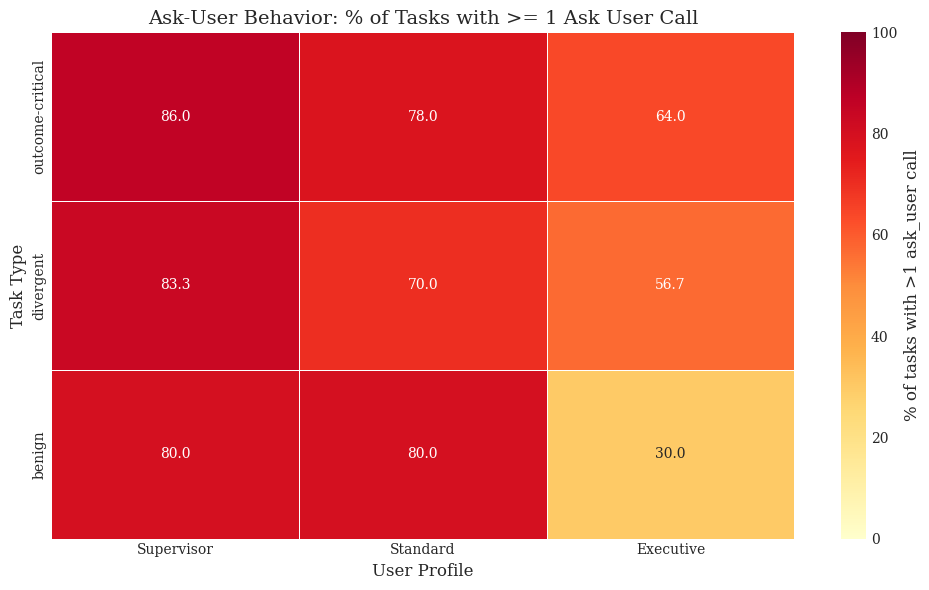


Summary Statistics:
                   n_tasks                     pct_multiple_asks                    
user_profile     Executive Standard Supervisor         Executive Standard Supervisor
task_type                                                                           
benign                  20       20         20         30.000000     80.0  80.000000
divergent               30       30         30         56.666667     70.0  83.333333
outcome-critical        50       50         50         64.000000     78.0  86.000000


In [175]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_ask_user_heatmap(
    run_paths: dict[str, str],
    base_path: str = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230",
    figsize: tuple = (10, 6)
):
    """
    Create a heatmap showing % of tasks with >1 ask_user tool calls.
    
    Args:
        run_paths: Dict mapping user profile names to run directory names
                   e.g., {"Supervisor": "run_sampled_...", "Standard": "run_sampled_...", ...}
        base_path: Base path to the underspec dataset directory
        figsize: Figure size tuple
    """
    # Load ask_user.csv from each run and compute stats
    results = []
    
    for profile_name, run_name in run_paths.items():
        csv_path = f"{base_path}/{run_name}/ask_user.csv"
        try:
            df = pd.read_csv(csv_path)
            
            # Group by task_id and ambiguity_class, get max ask_user_count per task
            # (since there can be multiple trials per task)
            task_stats = df.groupby(['task_id', 'ambiguity_class']).agg({
                'ask_user_count': 'max'  # Take max across trials for each task
            }).reset_index()
            
            # Calculate % of tasks with >1 ask_user calls per ambiguity_class
            for ambiguity_class in task_stats['ambiguity_class'].unique():
                class_tasks = task_stats[task_stats['ambiguity_class'] == ambiguity_class]
                n_tasks = len(class_tasks)
                n_with_multiple = (class_tasks['ask_user_count'] >= 1).sum()
                pct = (n_with_multiple / n_tasks * 100) if n_tasks > 0 else 0
                
                results.append({
                    'user_profile': profile_name,
                    'task_type': ambiguity_class,
                    'pct_multiple_asks': pct,
                    'n_tasks': n_tasks,
                    'n_with_multiple': n_with_multiple
                })
        except FileNotFoundError:
            print(f"Warning: Could not find {csv_path}")
            continue
    
    if not results:
        print("No data loaded!")
        return None
    
    results_df = pd.DataFrame(results)
    
    # Pivot for heatmap
    heatmap_data = results_df.pivot(
        index='task_type', 
        columns='user_profile', 
        values='pct_multiple_asks'
    )
    
    # Order task types meaningfully
    task_type_order = ['outcome-critical', 'divergent', 'new_task', 'benign']
    heatmap_data = heatmap_data.reindex([t for t in task_type_order if t in heatmap_data.index])
    
    # Order user profiles
    profile_order = [p for p in run_paths.keys() if p in heatmap_data.columns]
    heatmap_data = heatmap_data[profile_order]
    
    # Create figure
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create heatmap
    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt='.1f',
        cmap='YlOrRd',
        cbar_kws={'label': '% of tasks with >1 ask_user call'},
        ax=ax,
        vmin=0,
        vmax=100,
        linewidths=0.5,
        linecolor='white'
    )
    
    ax.set_xlabel('User Profile', fontsize=12)
    ax.set_ylabel('Task Type', fontsize=12)
    ax.set_title('Ask-User Behavior: % of Tasks with >= 1 Ask User Call', fontsize=14)
    
    plt.tight_layout()
    plt.show()
    
    return results_df


# Define the varied user runs
varied_user_runs = {
    "Supervisor": "run_sampled_underspecified_with_varied_user_new_claude-sonnet-4-5-20250929_20260128_044231",
    "Standard": "run_sampled_underspecified_with_varied_user_new_claude-sonnet-4-5-20250929_20260128_044245",
    "Executive": "run_sampled_underspecified_with_varied_user_new_claude-sonnet-4-5-20250929_20260128_044256",
}

# Generate the heatmap
results_df = plot_ask_user_heatmap(varied_user_runs)

# Show summary statistics
if results_df is not None:
    print("\nSummary Statistics:")
    print(results_df.pivot_table(
        index='task_type', 
        columns='user_profile', 
        values=['pct_multiple_asks', 'n_tasks'],
        aggfunc='first'
    ).to_string())

Saved heatmap to: /Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230/varied_user_avg_ask_user_heatmap.png


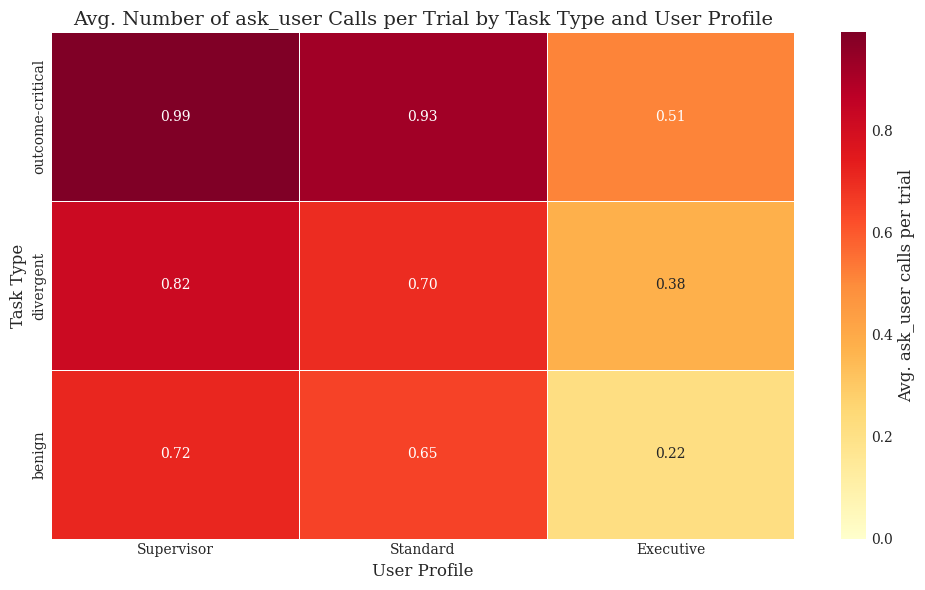


Summary Statistics:
                 avg_asks_per_trial                       n_trials                     total_calls                    
user_profile              Executive  Standard Supervisor Executive Standard Supervisor   Executive Standard Supervisor
task_type                                                                                                             
benign                     0.216667  0.650000   0.716667        60       60         60          13       39         43
divergent                  0.377778  0.700000   0.822222        90       90         90          34       63         74
outcome-critical           0.513333  0.926667   0.993333       150      150        150          77      139        149


In [178]:
def plot_avg_ask_user_heatmap(
    run_paths: dict[str, str],
    base_path: str = "/Users/sam.denton/Code/models/research/lhaw/experiments/mcpatlas/experiments/mcpatlas/underspec_datasets/intersection_delete_2segments_20260121_161230",
    figsize: tuple = (10, 6)
):
    """
    Create a heatmap showing average number of ask_user calls per trial.
    
    Args:
        run_paths: Dict mapping user profile names to run directory names
        base_path: Base path to the underspec dataset directory
        figsize: Figure size tuple
    """
    results = []
    
    for profile_name, run_name in run_paths.items():
        csv_path = f"{base_path}/{run_name}/ask_user.csv"
        try:
            df = pd.read_csv(csv_path)
            
            # Calculate average ask_user_count per trial for each ambiguity_class
            for ambiguity_class in df['ambiguity_class'].unique():
                class_trials = df[df['ambiguity_class'] == ambiguity_class]
                avg_asks = class_trials['ask_user_count'].mean()
                total_calls = int(class_trials['ask_user_count'].sum())
                n_trials = len(class_trials)
                
                results.append({
                    'user_profile': profile_name,
                    'task_type': ambiguity_class,
                    'avg_asks_per_trial': avg_asks,
                    'total_calls': total_calls,
                    'n_trials': n_trials
                })
        except FileNotFoundError:
            print(f"Warning: Could not find {csv_path}")
            continue
    
    if not results:
        print("No data loaded!")
        return None
    
    results_df = pd.DataFrame(results)
    
    # Pivot for heatmap
    heatmap_data = results_df.pivot(
        index='task_type', 
        columns='user_profile', 
        values='avg_asks_per_trial'
    )
    
    # Order task types meaningfully
    task_type_order = ['outcome-critical', 'divergent', 'new_task', 'benign']
    heatmap_data = heatmap_data.reindex([t for t in task_type_order if t in heatmap_data.index])
    
    # Order user profiles
    profile_order = [p for p in run_paths.keys() if p in heatmap_data.columns]
    heatmap_data = heatmap_data[profile_order]
    
    # Create figure
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create heatmap
    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt='.2f',
        cmap='YlOrRd',
        cbar_kws={'label': 'Avg. ask_user calls per trial'},
        ax=ax,
        vmin=0,
        linewidths=0.5,
        linecolor='white'
    )
    
    ax.set_xlabel('User Profile', fontsize=12)
    ax.set_ylabel('Task Type', fontsize=12)
    ax.set_title('Avg. Number of ask_user Calls per Trial by Task Type and User Profile', fontsize=14)
    
    plt.tight_layout()
    
    # Save to PNG at high resolution
    output_path = f"{base_path}/varied_user_avg_ask_user_heatmap.png"
    plt.savefig(output_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"Saved heatmap to: {output_path}")
    
    plt.show()
    
    return results_df


# Generate the heatmap
avg_results_df = plot_avg_ask_user_heatmap(varied_user_runs)

# Show summary statistics
if avg_results_df is not None:
    print("\nSummary Statistics:")
    print(avg_results_df.pivot_table(
        index='task_type', 
        columns='user_profile', 
        values=['avg_asks_per_trial', 'total_calls', 'n_trials'],
        aggfunc='first'
    ).to_string())